## Example notebook for building custom stellar populations with BPASS
### Note: This notebook requires stellar libraries. I am using BPASS v2.3, details of which can be found [here](https://warwick.ac.uk/fac/sci/physics/research/astro/research/catalogues/bpass/bpassv2p3/bpassv2p3_release_paper.pdf).

In [ ]:
# Import necessary modules
from hoki import load
from hoki.spec import dopcor
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from astropy.io import ascii
from astropy.table import Table

# Plotting parameters
plt.rcParams['xtick.major.size'] = 6
plt.rcParams['xtick.major.width'] = 1
plt.rcParams['xtick.minor.size'] = 3
plt.rcParams['xtick.minor.visible'] = True
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.major.size'] = 6
plt.rcParams['ytick.minor.size'] = 3
plt.rcParams['ytick.minor.visible'] = True
plt.rcParams['ytick.major.width'] = 1
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['xtick.labelsize']=16
plt.rcParams['ytick.labelsize']=16

plt.rcParams.update({
    "text.usetex": True,
    "font.family": 'Andale',
    'figure.dpi': 300
})

## 1. Load stellar populations
BPASS stellar libraries encode information on each template in their name, for example:

'spectra-bin-imf135_300.C3K.z001.a+00.dat'
- imf135_300 (Used IMF)
- .C3K. (Underlying stellar libraries)
- .z001. (Stellar metallicity)
- .a+00. (Alpha enhancement)

Each spectrum is produced assuming a burst of 1e6 solar masses at a given time.

In the example below I produce a spectrum produced by two stellar populations of the same metallicity, one old population (Age=1Gyr) and one young population (Age=1Myr). The young population is considerably less massive than the older stellar population.

In [ ]:
SL_DIRECTORY = '../spectra-bin_byrne23/' # Your directory to the stellar libraries
STELLAR_LIBRARY = 'C3K' # It is recommended to draw from the same stellar libraries

# Define the combination of metallicities, ages, alpha enhancements and masses you want to produce
MET = [0.01, 0.10]  # Metallicity in solar units
A_E = [0,0]         # Alpha-enhancement
AGE = [6.0, 9.0]    # Age in log10(yr)
MASS = [1e6, 1e9]   # Mass in solar masses


wavelengths = []
fluxes = []
for me, a, ae, ma in zip(MET,AGE,A_E,MASS):
    lib = load.model_output(SL_DIRECTORY+'spectra-bin-imf135_300.%s.z%s.a+0%i.dat'%(STELLAR_LIBRARY,str("%.2f"%me).replace('.',''),ae))
    wavelengths.append(lib.WL)
    fluxes.append(lib[str(a)]*(ma/1e6))

rest_wl = wavelengths[0] # If stellar libraries are consistent, the wavelength axis will always be the same
combined_flux = np.nansum(fluxes, axis=0)


## 2. View overall stellar populations
This is a good check to make sure the stellar populations being worked with look reasonable.

Text(0.85, 0.9, 'Combined Population')

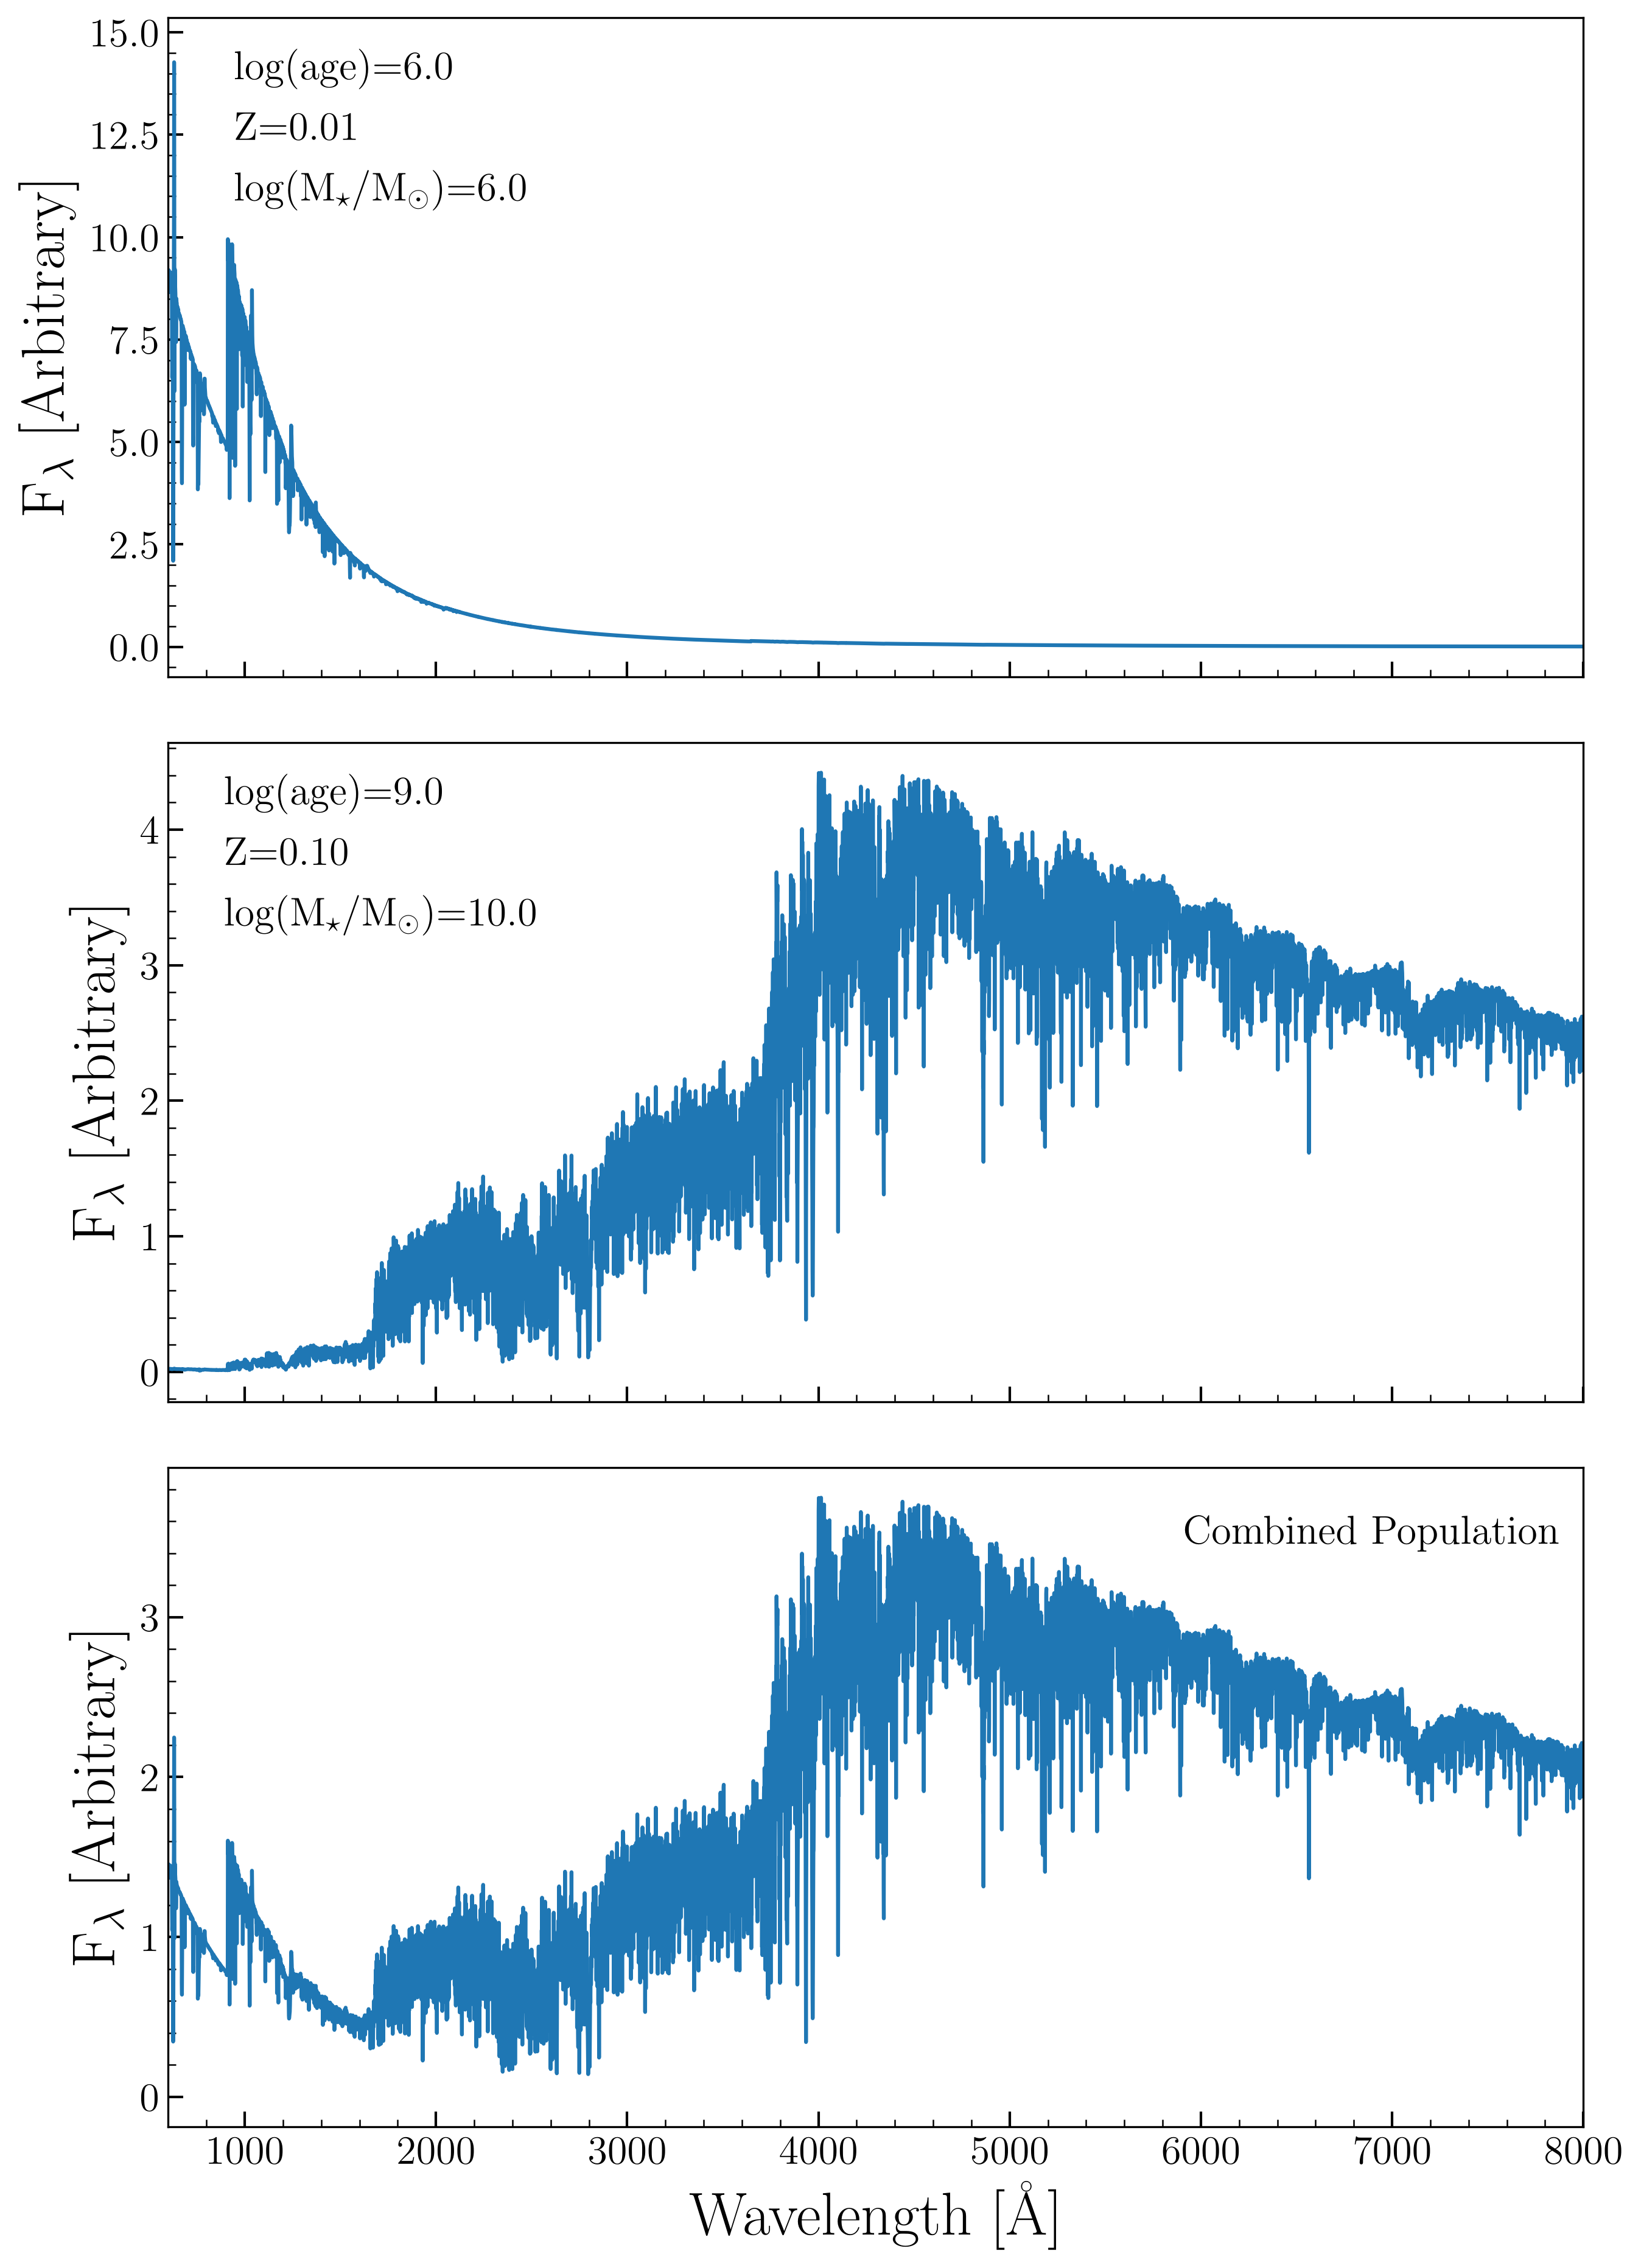

In [27]:
NORM_POINT = 2000   # Normalisation wavelength (for visualisation)
norm_ind = np.abs(np.array(rest_wl) - NORM_POINT).argmin()

fig, ax = plt.subplots(3,1,figsize=(10,15), sharex=True)
plt.subplots_adjust(hspace=0.1)

ax[0].plot(rest_wl, fluxes[0]/fluxes[0][norm_ind],label=r'Age=1e6 yr \\ Z=0.01 \\ $\rm{M_\star=5.0^6~M_\odot}$')
ax[1].plot(rest_wl, fluxes[1]/fluxes[1][norm_ind])
ax[2].plot(rest_wl, combined_flux/combined_flux[norm_ind])

for a, age, met, mass in zip(ax,AGE,MET,MASS):
    a.text(0.15, 0.83, r'\noindent log(age)=%.1f \\ \\ Z=%.2f \\ \\ $\rm{log(M_\star/M_\odot)}$=%.1f  '%(age,met,np.log10(mass)), 
           ha='center', va='center', transform = a.transAxes, fontsize=16)

for a in ax:
    a.set_xlim(600, 8000)
    a.set_ylabel(r'F$_\lambda$ [Arbitrary]', fontsize=24)

ax[2].set_xlabel(r'Wavelength [$\rm \AA$]', fontsize=24)
ax[2].text(0.85,0.9,r'Combined Population', ha='center', va='center', transform = ax[2].transAxes, fontsize=16)

## 3. Export the spectrum for use in cloudy
Cloudy does not care about flux scaling and can accept multiple wavelength and flux density units. Here we work with Angstrom and F_lambda units. This needs to be specified in the resulting cloudy file.

In [23]:
# Since cloudy requires additional information in the first line, the quickest approach is to write the spectrum line by line

OUT_DIR = './'

with open(OUT_DIR+'test_spec.dat', 'w') as f:
    for i, (wl, fl) in enumerate(zip(rest_wl, combined_flux)):
        if i == 0:
            f.write(f"{wl:.6e} {fl:.6e} Flambda units angstrom\n")
        else:
            f.write(f"{wl:.6e} {fl:.6e}\n")

## 4. Set-up the cloudy file.


In [17]:
# Check if a parameter is varied or not
def is_varied(value):
    return isinstance(value, (list, tuple))
 

# Get the grid parameters
def grid_line(value):
    lo, hi, step = sorted(value[:2]) + [abs(value[2])]
    return lo, f'grid {lo} {hi} {step}'
 

# Format lines to match cloudy's input
def param_lines(command, value, suffix=''):
    if is_varied(value):
        start, grid = grid_line(value)
        return [f'{command} {start}{suffix} vary', grid]
    return [f'{command} {value}{suffix}']
 


In [18]:
# Paramters for the cloudy config file

"""
IMPORTANT: Varied values should be stated in the form [MIN, MAX, STEP]
"""

TITLE = 'Test Example'      # Top matter
FILE_OUT = 'test2'           # Name for output files - Follows the structure 

LINE_LIST = 'line_list.dat' # List of emission lines you are interested in

# SED
SED_NAME = 'test_spec.dat'  # Name of the produced SED file
SCALE_LUM = 40              # The luminosity to scale the SED to (log(L/(erg/s)))
LOG_U = -2                  # Ionisation paramter

# CMB + Cosmic rays
USE_CMB = True              # Use the CMB (recommended)
USE_COSMIC_RAYS = True      # Use cosmic rays (Also recommended)

# Cloud geometry
CLOUD_RADIUS = 20           # Radius of the cloud in log(cm)
CLOUD_CONSTANT = 'density'  # Constant density or pressure

# Cloud properties
ABUNDANCE = 'solar'         # Solar abundances
HDEN = [2,4,1]              # Hydrogen density in log(cm^3)
GAS_MET = [0,-2,0.5]    # Gas-phase metallicity in log(Z_gas/Z_sol)

# Stopping conditions
STOP_TEMP = True            # Stop at minimum temperature
STOP_TEMP_VALUE = 1000      # Temprature to stop at
STOP_EFRAC = True           # Stop at minimum electron fraction
STOP_EFRAC_VALUE = 0.01     # Electron fraction to stop at

# Files to save
SAVE_OVERVIEW = True        # Save the overview file
SAVE_CONTINUUM = True       # Save the resulting spectrum
SAVE_LINES = True           # Save emission lines
SAVE_GRID = True            # Save the parameter grid




In [19]:
lines = [f'title {TITLE}']

# SED
lines += ['# SED',
            f'table SED "{SED_NAME}" luminosity "{SCALE_LUM}"']
lines += param_lines('ionization parameter', LOG_U)

# CMB and COSMIC Rays
if USE_CMB:
    lines+=['# CMB','CMB']
if USE_COSMIC_RAYS:
    lines+=['# Cosmic rays','cosmic ray background']

# Cloud geometry
radius = CLOUD_RADIUS
lines += ['# Geometry', *param_lines('radius', radius)]

if CLOUD_CONSTANT == 'pressure':
    lines.append('constant pressure')
elif CLOUD_CONSTANT == 'density':
    lines.append('constant density')

# Cloud properties
lines.append('# Cloud properties')

lines.append('abundances solar_GASS10')
lines += param_lines('hden', HDEN)               
lines += param_lines('metals', GAS_MET, ' log') 

# Stopping conditions
lines.append('# Stopping conditions')
if STOP_TEMP:
    lines.append(f'stop temperature {STOP_TEMP_VALUE} linear')
if STOP_EFRAC:
    lines.append(f'stop efrac {STOP_EFRAC_VALUE} linear')

# Output files
lines.append('# Save files')
if SAVE_OVERVIEW:
    lines.append(f'save overview "{FILE_OUT}.ovr" last')
if SAVE_CONTINUUM:
    lines.append(f'save continuum "{FILE_OUT}.con" last')
if SAVE_LINES:
    lines.append(f'save line list "{FILE_OUT}.lin" "{LINE_LIST}" absolute last')
if SAVE_GRID:
    lines.append(f'save grid "{FILE_OUT}.grd" last')

file = '\n'.join(lines) + '\n'

with open(FILE_OUT + '.in', 'w') as f:
        f.write(file)

## 5. Run cloudy!
Make sure your list of lines, cloudy input file, and stellar spectrum are all in the same directory. Then run cloudy your usual way.